# Factores asociados a la supervivencia en el naufragio del Titanic: un análisis exploratorio reproducible

**MCDI503 Exploración Inteligente para la Ciencia de Datos · Avance del proyecto, Fase 1 (Evaluación sumativa 1)**

Magíster en Ciencia de Datos e Inteligencia Artificial, Universidad Andrés Bello

Docente: Raúl Alonso Calvo 

Noviembre de 2026

## I. Identificación del proyecto

| Elemento | Detalle |
|---|---|
| Integrantes (Grupo 8) | Matías Manríquez Ortiz, Daniel Pérez Ramírez, Abigail Robles Chávez, Roberto Sánchez Saldivia |
| Conjunto de datos | `titanic` de la biblioteca seaborn (`sns.load_dataset("titanic")`), versión del conjunto de entrenamiento de la competencia *Titanic: Machine Learning from Disaster* de Kaggle |
| Unidad de análisis | El pasajero (una fila por persona): 891 filas y 15 columnas |
| Propósito | Diagnosticar la calidad de los datos, tomar las primeras decisiones de limpieza de forma trazable y describir cómo varía la supervivencia según sexo, clase, edad, tarifa y grupo familiar |

**Cómo ejecutar este notebook.** Usar *Kernel → Restart & Run All*. Requiere Python 3 con `pandas`, `numpy`, `matplotlib` y `seaborn` (versiones impresas en la sección 3.1). La **primera** ejecución necesita internet para descargar el dataset una sola vez; desde ahí se trabaja con la copia local `data/raw/titanic_raw.csv`. El notebook crea las carpetas `data/raw/` y `data/processed/` junto a la carpeta `notebooks/` (o junto al notebook, si se ejecuta en otra ubicación).

**Convención de lectura.** Cada bloque sigue la secuencia *pregunta o propósito → acción (código) → resultado*. Las decisiones se identifican como **D1 … D8** y las preguntas exploratorias como **P1 … P5**; ambos códigos se usan igual en el informe PDF.

## II. Contexto y objetivo exploratorio

**Contexto.** El 15 de abril de 1912 el RMS Titanic se hundió en su viaje inaugural tras chocar con un iceberg; murieron 1.502 de las 2.224 personas a bordo. Los botes no alcanzaban para todos, por lo que la supervivencia dependió del protocolo de evacuación («mujeres y niños primero») y de la posición de cada persona en el barco. El dataset registra, para 891 pasajeros, si sobrevivieron y sus características sociodemográficas y del viaje, lo que permite examinar esa desigualdad con datos.

**Objetivo exploratorio de la Fase 1.** Caracterizar la estructura y calidad del conjunto `titanic`, documentar las decisiones iniciales de limpieza y transformación, y obtener una primera descripción de cómo varía la proporción de sobrevivientes según los factores del proyecto.

**Preguntas exploratorias iniciales** (y dónde se responden):

| Código | Pregunta | Sección |
|---|---|---|
| P1 | ¿Cómo varía la proporción de sobrevivientes según sexo y clase? | 6.1 |
| P2 | ¿Difiere la edad entre sobrevivientes y no sobrevivientes («mujeres y niños primero»)? | 6.2 |
| P3 | ¿Cómo difiere la mediana de la tarifa entre sobrevivientes y no sobrevivientes dentro de cada clase?| 6.3 |
| P4 | ¿Cómo varía la proporción de sobrevivientes según el tamaño del grupo familiar? | 6.4 |
| P5 | ¿Los faltantes de `age` y `deck` se concentran en alguna clase y, de ser así, eliminar esas filas distorsionaría las conclusiones sobre quién sobrevivió? | 3.4 y 6.5 |

## III. Carga y revisión inicial de datos

### 3.1 Entorno y versiones
**Propósito:** dejar registro de las bibliotecas y versiones con que se obtuvieron los resultados, para que otra persona pueda reproducirlos.

In [1]:
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

print("Python    ", platform.python_version())
print("pandas    ", pd.__version__)
print("numpy     ", np.__version__)
print("matplotlib", matplotlib.__version__)
print("seaborn   ", sns.__version__)

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)

# Estilo común de figuras: grilla tenue y paleta fija (azul = serie 1, naranjo = serie 2)
AZUL, NARANJO, GRIS = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e5e5e2", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.labelsize": 10,
})

Python     3.14.7
pandas     3.0.6
numpy      2.5.3
matplotlib 3.11.2
seaborn    0.13.2


### 3.2 Carga del conjunto de datos
**Acción:** se descarga el dataset **una sola vez** y se guarda en `data/raw/titanic_raw.csv`; todas las ejecuciones posteriores leen esa copia, que nunca se modifica. Así los datos de entrada no cambian entre ejecuciones ni entre integrantes.

In [2]:
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RUTA_RAW = RAIZ / "data" / "raw" / "titanic_raw.csv"
RUTA_PROC = RAIZ / "data" / "processed" / "titanic_fase1.csv"


def cargar_titanic(ruta: Path) -> pd.DataFrame:
    """Devuelve el dataset crudo; lo descarga desde seaborn solo si no existe la copia local."""
    if not ruta.exists():
        ruta.parent.mkdir(parents=True, exist_ok=True)
        sns.load_dataset("titanic").to_csv(ruta, index=False)
        print("Copia cruda creada en", ruta.relative_to(RAIZ))
    else:
        print("Leyendo copia cruda existente:", ruta.relative_to(RAIZ))
    return pd.read_csv(ruta)


df_raw = cargar_titanic(RUTA_RAW)

# Verificaciones de los datos de entrada (si alguna falla, el dataset no es el esperado)
assert df_raw.shape == (891, 15), "Dimensión distinta a la esperada"
assert df_raw["survived"].sum() == 342, "Número de sobrevivientes distinto al esperado"
assert df_raw.isna().sum().sum() == 869, "Número total de faltantes distinto al esperado"
print("Dimensión:", df_raw.shape, "| verificaciones de entrada OK")

Leyendo copia cruda existente: data\raw\titanic_raw.csv
Dimensión: (891, 15) | verificaciones de entrada OK


### 3.3 Estructura y tipos de datos
**Pregunta:** ¿qué variables tiene el dataset y con qué tipo se leen?

In [3]:
df_raw.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


**Resultado.** 891 filas (pasajeros) y 15 columnas: 6 numéricas (`survived`, `pclass`, `age`, `sibsp`, `parch`, `fare`), 7 de texto (`sex`, `embarked`, `class`, `who`, `deck`, `embark_town`, `alive`) y 2 lógicas (`adult_male`, `alone`). `survived` y `pclass` se leen como enteros, pero conceptualmente son binaria y ordinal, respectivamente. Solo `age`, `deck`, `embarked` y `embark_town` tienen valores no nulos menores a 891.

### 3.4 Estado general: faltantes, duplicados, columnas repetidas y valores llamativos
**Pregunta:** ¿qué problemas de calidad hay que resolver o documentar antes de explorar? (incluye la primera mirada a P5)

In [5]:
faltantes = pd.DataFrame({
    "n_faltantes": df_raw.isna().sum(),
    "pct_faltantes": (df_raw.isna().mean() * 100).round(1),
})
faltantes[faltantes["n_faltantes"] > 0].sort_values("n_faltantes", ascending=False)

,n_faltantes,pct_faltantes
deck,688,77.2
age,177,19.9
embarked,2,0.2
embark_town,2,0.2


In [6]:
print("Filas duplicadas exactas:", df_raw.duplicated().sum())
dup = df_raw[df_raw.duplicated(keep=False)]
print("Filas involucradas en duplicados, por clase:", dup["pclass"].value_counts().sort_index().to_dict())
print("Filas involucradas en duplicados, por sexo: ", dup["sex"].value_counts().to_dict())

Filas duplicadas exactas: 107
Filas involucradas en duplicados, por clase: {1: 4, 2: 31, 3: 125}
Filas involucradas en duplicados, por sexo:  {'male': 127, 'female': 33}


In [7]:
# ¿Qué columnas repiten información de otras? (tablas cruzadas 1 a 1)
print(pd.crosstab(df_raw["class"], df_raw["pclass"]), "\n")
print(pd.crosstab(df_raw["alive"], df_raw["survived"]), "\n")
print(pd.crosstab(df_raw["embark_town"], df_raw["embarked"]), "\n")
print("alone equivale a sibsp + parch == 0:",
      (df_raw["alone"] == (df_raw["sibsp"] + df_raw["parch"] == 0)).all())
print("adult_male equivale a who == 'man':", (df_raw["adult_male"] == (df_raw["who"] == "man")).all())

pclass    1    2    3
class                
First   216    0    0
Second    0  184    0
Third     0    0  491 

survived    0    1
alive             
no        549    0
yes         0  342 

embarked       C   Q    S
embark_town              
Cherbourg    168   0    0
Queenstown     0  77    0
Southampton    0   0  644 

alone equivale a sibsp + parch == 0: True
adult_male equivale a who == 'man': True


In [8]:
# ¿Cómo clasifica `who` a los pasajeros SIN edad registrada?
print("who entre los 177 pasajeros sin edad:", df_raw.loc[df_raw["age"].isna(), "who"].value_counts().to_dict())
print(df_raw.groupby("who")["age"].agg(["min", "max", "count"]))

who entre los 177 pasajeros sin edad: {'man': 124, 'woman': 53}
         min   max  count
who                      
child   0.42  15.0     83
man    16.00  80.0    413
woman  16.00  63.0    218


In [9]:
print("Tarifas en cero:", (df_raw["fare"] == 0).sum(),
      "| por clase:", df_raw.loc[df_raw["fare"] == 0, "pclass"].value_counts().sort_index().to_dict())
print("Edad: mínimo", df_raw["age"].min(), "| máximo", df_raw["age"].max())
print("sibsp:", df_raw["sibsp"].value_counts().sort_index().to_dict())
print("parch:", df_raw["parch"].value_counts().sort_index().to_dict())
print("Cubiertas:", sorted(df_raw["deck"].dropna().unique()))

Tarifas en cero: 15 | por clase: {1: 5, 2: 6, 3: 4}
Edad: mínimo 0.42 | máximo 80.0
sibsp: {0: 608, 1: 209, 2: 28, 3: 16, 4: 18, 5: 5, 8: 7}
parch: {0: 678, 1: 118, 2: 80, 3: 5, 4: 4, 5: 5, 6: 1}
Cubiertas: ['A', 'B', 'C', 'D', 'E', 'F', 'G']


**Resultado de la revisión inicial (insumo de la sección V):**
- **Faltantes:** `deck` 688 (77,2 %), `age` 177 (19,9 %), `embarked` y `embark_town` 2 cada una (0,2 %).
- **Duplicados:** 107 filas idénticas; las filas involucradas son mayoritariamente hombres de 3.ª clase.
- **Columnas repetidas:** `class` = `pclass`, `alive` = `survived`, `embark_town` = `embarked`, `adult_male` = (`who` == "man") y `alone` = (`sibsp + parch` == 0).
- **Hallazgo de calidad:** `who` clasifica a los 177 pasajeros sin edad como adultos (124 *man* y 53 *woman*). Si se usara `who` para estudiar a los niños, esos casos quedarían mal clasificados.
- **Valores llamativos:** 15 tarifas en cero (en las tres clases); edad entre 0,42 y 80 años; `sibsp` llega a 8 y `parch` a 6.

## IV. Exploración preliminar

### 4.1 Resumen descriptivo de las variables numéricas
**Pregunta:** ¿qué rango, centro y dispersión tienen las variables numéricas?

In [10]:
df_raw[['age', 'sibsp', 'parch', 'fare']].describe().round(2)

,age,sibsp,parch,fare
count,714.00,891.00,891.00,891.00
mean,29.70,0.52,0.38,32.20
std,14.53,1.10,0.81,49.69
min,0.42,0.00,0.00,0.00
25%,20.12,0.00,0.00,7.91
50%,28.00,0.00,0.00,14.45
75%,38.00,1.00,0.00,31.00
max,80.00,8.00,6.00,512.33


**Resultado.** La mediana de edad es 28 años (media 29,7). `fare` es muy asimétrica: media 32,20 frente a mediana 14,45 y máximo 512,33. En `sibsp` y `parch`, al menos el 50 % de los pasajeros tiene 0, pero hay valores extremos (8 y 6).

### 4.2 Variables categóricas y variable de interés
**Pregunta:** ¿cómo se reparten los pasajeros por sexo, clase y puerto, y qué proporción sobrevivió?

In [11]:
for col in ["survived", "sex", "pclass", "embarked"]:
    tabla = pd.DataFrame({
        "n": df_raw[col].value_counts(dropna=False).sort_index(),
        "pct": (df_raw[col].value_counts(normalize=True, dropna=False).sort_index() * 100).round(1),
    })
    print(f"--- {col} ---\n{tabla}\n")

--- survived ---
            n   pct
survived           
0         549  61.6
1         342  38.4

--- sex ---
          n   pct
sex              
female  314  35.2
male    577  64.8

--- pclass ---
          n   pct
pclass           
1       216  24.2
2       184  20.7
3       491  55.1

--- embarked ---
            n   pct
embarked           
C         168  18.9
Q          77   8.6
S         644  72.3
NaN         2   0.2



**Resultado.** Sobrevivió el 38,4 % (342 de 891). Hay más hombres (64,8 %) que mujeres, más de la mitad viajaba en 3.ª clase (55,1 %) y la mayoría embarcó en Southampton (72,3 %). El grupo de Queenstown es pequeño (77 pasajeros), lo que limita las comparaciones por puerto.

### 4.3 Distribución de edad y tarifa (Figura 1)
**Pregunta:** ¿qué forma tienen las dos variables continuas? Esto orienta la decisión D7 sobre `fare`.

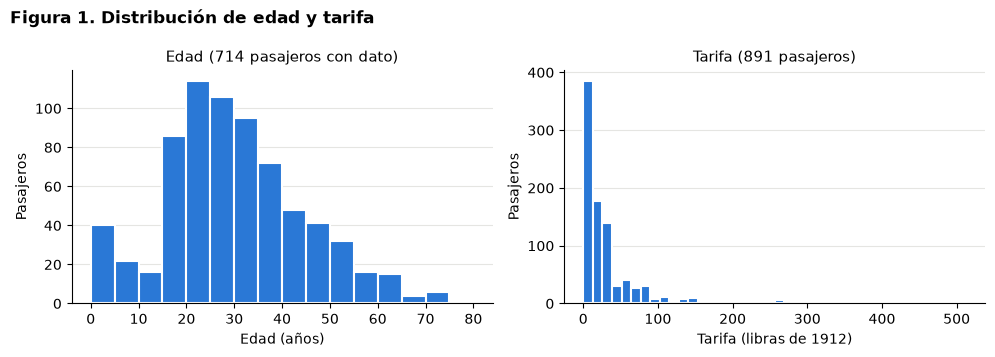

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(df_raw["age"].dropna(), bins=range(0, 85, 5), color=AZUL, edgecolor="white", linewidth=1.5)
axes[0].set(title="Edad (714 pasajeros con dato)", xlabel="Edad (años)", ylabel="Pasajeros")
axes[1].hist(df_raw["fare"], bins=40, color=AZUL, edgecolor="white", linewidth=1.5)
axes[1].set(title="Tarifa (891 pasajeros)", xlabel="Tarifa (libras de 1912)", ylabel="Pasajeros")
fig.suptitle("Figura 1. Distribución de edad y tarifa", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()

**Resultado.** La edad se concentra entre 20 y 40 años, con un grupo visible de niños menores de 5 años. La tarifa tiene una cola larga a la derecha: casi todos pagaron menos de 100 libras y unos pocos más de 500. Esa asimetría hace que la media no represente bien a un pasajero típico y que un gráfico en escala original comprima a la mayoría en una sola barra.

## V. Decisiones y transformaciones iniciales

Cada decisión se implementa como una función que **recibe y devuelve un DataFrame**, sin modificar `df_raw`. La función `registrar` deja constancia de la dimensión después de cada paso; la tabla final (sección 5.9) es la bitácora de decisiones de esta fase.

In [13]:
bitacora = []

def registrar(df: pd.DataFrame, codigo: str, decision: str) -> pd.DataFrame:
    bitacora.append({"código": codigo, "decisión": decision, "filas": df.shape[0], "columnas": df.shape[1]})
    print(f"{codigo}: {decision} -> {df.shape[0]} filas x {df.shape[1]} columnas")
    return df

df = registrar(df_raw.copy(), "D0", "Copia de trabajo de los datos crudos")

D0: Copia de trabajo de los datos crudos -> 891 filas x 15 columnas


### 5.1 D1 · Conservar las 107 filas duplicadas
**Decisión:** no eliminar duplicados. **Motivo:** el archivo original de Kaggle identifica a cada pasajero con un `PassengerId` único, por lo que las 891 filas son personas distintas. Las filas idénticas aparecen porque seaborn eliminó nombre, ticket e identificador; quedan pasajeros con los mismos atributos (en su mayoría hombres de 3.ª clase). Eliminarlas borraría personas reales y sesgaría la muestra hacia 1.ª y 2.ª clase.

In [14]:
df = registrar(df, "D1", "Se conservan las filas duplicadas (son pasajeros distintos)")
assert len(df) == 891

D1: Se conservan las filas duplicadas (son pasajeros distintos) -> 891 filas x 15 columnas


### 5.2 D2 · Eliminar las columnas que repiten información
**Decisión:** quitar `class`, `alive`, `embark_town`, `adult_male` y `alone`. **Motivo:** la sección 3.4 mostró que cada una equivale exactamente a otra columna o a una operación sobre ella; mantenerlas duplica información y puede llevar a contar dos veces el mismo efecto.

In [15]:
def quitar_redundantes(d: pd.DataFrame) -> pd.DataFrame:
    return d.drop(columns=["class", "alive", "embark_town", "adult_male", "alone"])

df = registrar(quitar_redundantes(df), "D2", "Se eliminan 5 columnas redundantes")

D2: Se eliminan 5 columnas redundantes -> 891 filas x 10 columnas


### 5.3 D3 · No usar `who` como variable de edad
**Decisión:** eliminar `who` y construir un grupo etario a partir de `age` (D8). **Motivo:** `who` clasifica como adultos a los 177 pasajeros sin edad (sección 3.4), lo que inflaría el grupo de adultos y ocultaría el faltante. El nuevo grupo etario mantiene a esos casos en una categoría explícita «Sin dato».

In [16]:
df = registrar(df.drop(columns=["who"]), "D3", "Se elimina who (asigna adulto a quien no tiene edad)")

D3: Se elimina who (asigna adulto a quien no tiene edad) -> 891 filas x 9 columnas


### 5.4 D4 · No imputar `age` en esta fase y marcar los faltantes
**Decisión:** conservar los 177 faltantes como NA y crear la bandera `edad_faltante`. **Motivo:** comparar la supervivencia entre quienes tienen y no tienen edad muestra si los faltantes podrían sesgar el análisis; si difieren, imputar con la media o la mediana no sería neutro. La imputación se evaluará en la fase de transformación.

In [17]:
df = df.assign(edad_faltante=df["age"].isna())
print(df.groupby("edad_faltante")["survived"].agg(["mean", "size"]).round(3))
df = registrar(df, "D4", "Se agrega la bandera edad_faltante (sin imputar)")

                mean  size
edad_faltante             
False          0.406   714
True           0.294   177
D4: Se agrega la bandera edad_faltante (sin imputar) -> 891 filas x 10 columnas


**Resultado intermedio.** Sobrevivió el 40,6 % de quienes tienen edad registrada y solo el 29,4 % de quienes no la tienen. Los faltantes **no parecen aleatorios**: una imputación simple trasladaría ese sesgo. Por eso los análisis de edad (P2) se hacen con los 714 casos con dato y se informa aparte el grupo «Sin dato».

### 5.5 D5 · Mantener `deck` sin imputar y crear `cabina_registrada`
**Decisión:** no imputar ni analizar `deck` como variable y, en su lugar, crear `cabina_registrada` (si hay o no cubierta registrada). **Motivo:** con 77,2 % de faltantes, cualquier imputación inventaría la mayor parte de la columna, pero el hecho de tener o no cabina registrada sí puede contener información (se revisa en P5).

In [18]:
df = df.assign(cabina_registrada=df["deck"].notna())
print(df.groupby("pclass")["cabina_registrada"].mean().round(3))
df = registrar(df, "D5", "Se agrega cabina_registrada; deck no se imputa")

pclass
1    0.810
2    0.087
3    0.024
Name: cabina_registrada, dtype: float64
D5: Se agrega cabina_registrada; deck no se imputa -> 891 filas x 11 columnas


**Resultado intermedio.** Tiene cubierta registrada el 81,0 % de los pasajeros de 1.ª clase, pero solo el 8,7 % de 2.ª y el 2,4 % de 3.ª. El faltante de `deck` depende de la clase, lo que respalda el supuesto de la Fase 1 formativa (se profundiza en 6.5).

### 5.6 D6 · Conservar los 2 faltantes de `embarked`
**Decisión:** dejarlos como NA. **Motivo:** son 2 casos (0,2 %); ninguna pregunta de esta fase depende del puerto, y completarlos con la moda («S») no cambiaría ningún resultado, pero agregaría un dato inventado.

In [19]:
df = registrar(df, "D6", "Se conservan los 2 NA de embarked")

D6: Se conservan los 2 NA de embarked -> 891 filas x 11 columnas


### 5.7 D7 · Tarifa: conservar los ceros y agregar una escala logarítmica
**Decisión:** mantener las 15 tarifas en cero (marcadas con `tarifa_cero`) y crear `tarifa_log = log(1 + fare)` solo para visualizar. **Motivo:** los ceros aparecen en las tres clases y podrían ser pasajes de cortesía o de tripulación en tránsito; sin evidencia de error, no se eliminan. La escala logarítmica reduce la asimetría vista en la Figura 1 (se usa `log1p` porque admite el cero).

In [20]:
df = df.assign(tarifa_cero=df["fare"].eq(0), tarifa_log=np.log1p(df["fare"]))
print("Asimetría de fare:     ", round(df["fare"].skew(), 2))
print("Asimetría de tarifa_log:", round(df["tarifa_log"].skew(), 2))
df = registrar(df, "D7", "Se agregan tarifa_cero y tarifa_log")

Asimetría de fare:      4.79
Asimetría de tarifa_log: 0.39
D7: Se agregan tarifa_cero y tarifa_log -> 891 filas x 13 columnas


**Resultado intermedio.** La asimetría baja de 4,79 a 0,39: en escala logarítmica la tarifa queda cerca de una distribución simétrica y las comparaciones entre grupos son más legibles. La variable original `fare` se conserva para los resúmenes (medianas).

### 5.8 D8 · Variables derivadas para P2 y P4
**Decisión:** crear `grupo_etario` (0–15, 16–29, 30–49, 50+ y «Sin dato»), `tamano_familia` (`sibsp + parch + 1`) y `tipo_familia` (Solo = 1, Pequeña = 2–4, Grande = 5+). **Motivo:** el corte en 16 años coincide con el que usa el propio dataset para definir «niño» en `who`, y agrupar el tamaño familiar evita conclusiones sobre categorías con muy pocos casos (por ejemplo, 7 personas en familias de 11).

In [21]:
def derivar_variables(d: pd.DataFrame) -> pd.DataFrame:
    grupo = pd.cut(d["age"], bins=[0, 16, 30, 50, 81], right=False,
                   labels=["0-15", "16-29", "30-49", "50+"])
    grupo = grupo.cat.add_categories("Sin dato").fillna("Sin dato")
    tam = d["sibsp"] + d["parch"] + 1
    tipo = pd.cut(tam, bins=[0, 1, 4, 20], labels=["Solo", "Pequeña (2-4)", "Grande (5+)"])
    return d.assign(grupo_etario=grupo, tamano_familia=tam, tipo_familia=tipo)

df = registrar(derivar_variables(df), "D8", "Se agregan grupo_etario, tamano_familia y tipo_familia")
print(df["grupo_etario"].value_counts().sort_index().to_dict())
print(df["tipo_familia"].value_counts().sort_index().to_dict())

D8: Se agregan grupo_etario, tamano_familia y tipo_familia -> 891 filas x 16 columnas
{'0-15': 83, '16-29': 301, '30-49': 256, '50+': 74, 'Sin dato': 177}
{'Solo': 537, 'Pequeña (2-4)': 292, 'Grande (5+)': 62}


### 5.9 Bitácora de decisiones y conjunto resultante
**Acción:** se verifica el conjunto transformado y se guarda en `data/processed/titanic_fase1.csv`, que será la entrada de la fase siguiente.

In [22]:
bitacora_df = pd.DataFrame(bitacora)
display(bitacora_df)

# Verificaciones de coherencia entre entrada, transformaciones y salida
assert df.shape == (891, 16)
assert df["survived"].sum() == df_raw["survived"].sum()          # no se perdieron sobrevivientes
assert df["edad_faltante"].sum() == df_raw["age"].isna().sum()   # la bandera coincide con los NA
assert (df["grupo_etario"] == "Sin dato").sum() == 177
assert df_raw.shape == (891, 15)                                 # los datos crudos no se modificaron

RUTA_PROC.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(RUTA_PROC, index=False)
print("Conjunto procesado guardado en", RUTA_PROC.relative_to(RAIZ), df.shape)
print("Columnas:", list(df.columns))

,código,decisión,filas,columnas
0,D0,Copia de trabajo de los datos crudos,891,15
1,D1,Se conservan las filas duplicadas (son pasajeros distintos),891,15
2,D2,Se eliminan 5 columnas redundantes,891,10
3,D3,Se elimina who (asigna adulto a quien no tiene edad),891,9
4,D4,Se agrega la bandera edad_faltante (sin imputar),891,10
5,D5,Se agrega cabina_registrada; deck no se imputa,891,11
6,D6,Se conservan los 2 NA de embarked,891,11
7,D7,Se agregan tarifa_cero y tarifa_log,891,13
8,D8,"Se agregan grupo_etario, tamano_familia y tipo_familia",891,16


Conjunto procesado guardado en data\processed\titanic_fase1.csv (891, 16)
Columnas: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'deck', 'edad_faltante', 'cabina_registrada', 'tarifa_cero', 'tarifa_log', 'grupo_etario', 'tamano_familia', 'tipo_familia']


## VI. Resultados e interpretación inicial

Todos los resultados de esta sección usan el conjunto procesado `df` (891 pasajeros). La proporción de sobrevivientes de referencia es 38,4 %.

In [23]:
def tasa(d: pd.DataFrame, por) -> pd.DataFrame:
    """Proporción de sobrevivientes (%) y número de pasajeros por grupo."""
    t = d.groupby(por, observed=False)["survived"].agg(sobrevive="mean", n="size")
    t["sobrevive"] = (t["sobrevive"] * 100).round(1)
    return t


def etiquetar(ax, barras, fmt="{:.0f} %", dentro=False):
    """Escribe el valor sobre cada barra (o dentro, en blanco, si dentro=True)."""
    for b in barras:
        ax.annotate(fmt.format(b.get_height()), (b.get_x() + b.get_width() / 2, b.get_height()),
                    ha="center", va="top" if dentro else "bottom", fontsize=9,
                    color="white" if dentro else GRIS,
                    xytext=(0, -4 if dentro else 2), textcoords="offset points")

### 6.1 P1 · Supervivencia según sexo y clase (Figura 2)
**Pregunta:** ¿cómo varía la proporción de sobrevivientes según sexo y clase?

        sobrevive    n
sex                   
female       74.2  314
male         18.9  577 

        sobrevive    n
pclass                
1            63.0  216
2            47.3  184
3            24.2  491 

Supervivencia (%) por clase y sexo:
 sex     female  male
pclass              
1         96.8  36.9
2         92.1  15.7
3         50.0  13.5


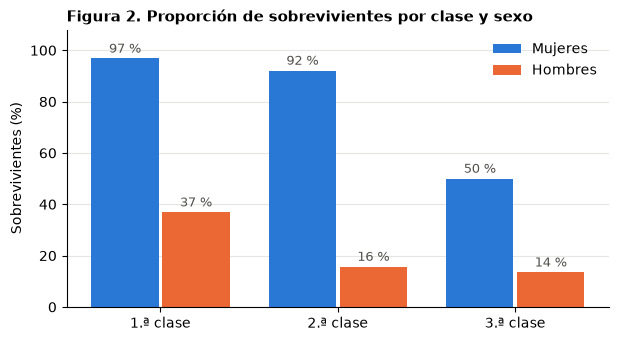

In [24]:
print(tasa(df, "sex"), "\n")
print(tasa(df, "pclass"), "\n")
p1 = df.pivot_table(index="pclass", columns="sex", values="survived", aggfunc="mean").mul(100).round(1)
print("Supervivencia (%) por clase y sexo:\n", p1)

fig, ax = plt.subplots(figsize=(7, 3.6))
x, w = np.arange(3), 0.38
b1 = ax.bar(x - w / 2 - 0.01, p1["female"], w, color=AZUL, label="Mujeres")
b2 = ax.bar(x + w / 2 + 0.01, p1["male"], w, color=NARANJO, label="Hombres")
etiquetar(ax, b1); etiquetar(ax, b2)
ax.set(xticks=x, xticklabels=["1.ª clase", "2.ª clase", "3.ª clase"], ylabel="Sobrevivientes (%)", ylim=(0, 108))
ax.legend(frameon=False, loc="upper right")
ax.set_title("Figura 2. Proporción de sobrevivientes por clase y sexo", loc="left", fontweight="bold")
plt.show()

**Interpretación.** El sexo es el factor más marcado: sobrevivió el 74,2 % de las mujeres y el 18,9 % de los hombres. La clase también ordena la supervivencia (63,0 % en 1.ª, 47,3 % en 2.ª y 24,2 % en 3.ª). Ambos factores se combinan: casi todas las mujeres de 1.ª y 2.ª clase sobrevivieron (96,8 % y 92,1 %), mientras que en 3.ª clase sobrevivió la mitad. Entre los hombres, solo los de 1.ª clase superan claramente al resto (36,9 % frente a 15,7 % y 13,5 %).

### 6.2 P2 · Edad y supervivencia (Figura 3)
**Pregunta:** ¿difiere la edad entre sobrevivientes y no sobrevivientes? ¿Se observa la regla «mujeres y niños primero»?

          median  mean  count
survived                     
0           28.0  30.6    424
1           28.0  28.3    290 

              sobrevive    n
grupo_etario                
0-15               59.0   83
16-29              35.5  301
30-49              41.8  256
50+                36.5   74
Sin dato           29.4  177


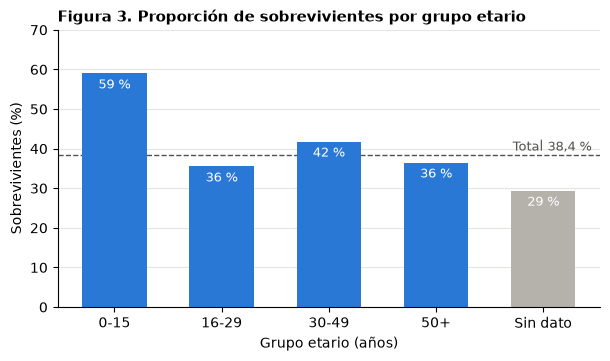

In [25]:
print(df.groupby("survived")["age"].agg(["median", "mean", "count"]).round(1), "\n")
p2 = tasa(df, "grupo_etario")
print(p2)

fig, ax = plt.subplots(figsize=(7, 3.6))
colores = [AZUL] * 4 + ["#b4b2ab"]
barras = ax.bar(p2.index.astype(str), p2["sobrevive"], color=colores, width=0.6)
etiquetar(ax, barras, dentro=True)
ax.axhline(38.4, color=GRIS, linewidth=1, linestyle="--", zorder=0.5)
ax.text(4.45, 39.5, "Total 38,4 %", ha="right", fontsize=9, color=GRIS)
ax.set(xlabel="Grupo etario (años)", ylabel="Sobrevivientes (%)", ylim=(0, 70))
ax.set_title("Figura 3. Proporción de sobrevivientes por grupo etario", loc="left", fontweight="bold")
plt.show()

**Interpretación.** La mediana de edad es la misma en ambos grupos (28 años) y la media difiere poco (30,6 frente a 28,3), por lo que la edad, mirada en conjunto, no separa a sobrevivientes de no sobrevivientes. La diferencia aparece en los extremos: sobrevivió el 59,0 % de los menores de 16 años, muy por sobre el resto de los grupos (35,5 % a 41,8 %). Esto es coherente con la prioridad para los niños. El grupo «Sin dato» (29,4 %) queda bajo el promedio, lo que confirma que los faltantes de edad no son neutros (D4).

### 6.3 P3 · Tarifa y supervivencia dentro de cada clase (Figura 4)
**Pregunta:** ¿Cómo difiere la mediana de la tarifa entre sobrevivientes y no sobrevivientes dentro de cada clase? Se compara la tarifa **dentro** de cada clase, porque la clase ya determina buena parte del precio.

Mediana de tarifa (libras) por clase y supervivencia:
         No sobrevivió  Sobrevivió
pclass                           
1               44.75       77.96
2               13.00       21.00
3                8.05        8.52


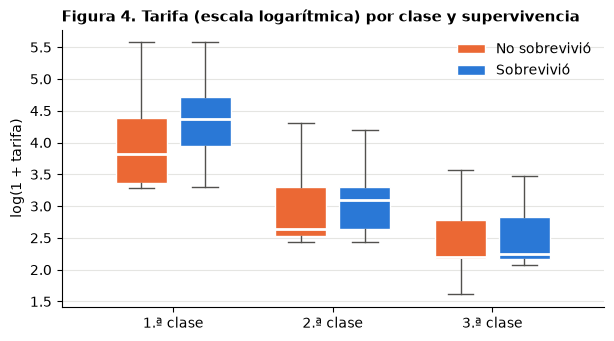

In [26]:
p3 = df.pivot_table(index="pclass", columns="survived", values="fare", aggfunc="median").round(2)
p3.columns = ["No sobrevivió", "Sobrevivió"]
print("Mediana de tarifa (libras) por clase y supervivencia:\n", p3)

fig, ax = plt.subplots(figsize=(7, 3.6))
datos = [df.loc[(df["pclass"] == c) & (df["survived"] == s), "tarifa_log"] for c in (1, 2, 3) for s in (0, 1)]
pos = [0.8, 1.2, 1.8, 2.2, 2.8, 3.2]
caja = ax.boxplot(datos, positions=pos, widths=0.32, patch_artist=True, showfliers=False,
                  medianprops={"color": "white", "linewidth": 2})
for i, parche in enumerate(caja["boxes"]):
    parche.set(facecolor=NARANJO if i % 2 == 0 else AZUL, edgecolor="white")
for elem in ("whiskers", "caps"):
    for l in caja[elem]:
        l.set(color=GRIS)
ax.set(xticks=[1, 2, 3], xticklabels=["1.ª clase", "2.ª clase", "3.ª clase"], ylabel="log(1 + tarifa)")
ax.legend([caja["boxes"][0], caja["boxes"][1]], ["No sobrevivió", "Sobrevivió"], frameon=False, loc="upper right")
ax.set_title("Figura 4. Tarifa (escala logarítmica) por clase y supervivencia", loc="left", fontweight="bold")
plt.show()

**Interpretación.** Dentro de 1.ª clase, los sobrevivientes pagaron una mediana de 77,96 libras frente a 44,75 de quienes murieron; en 2.ª clase, 21,00 frente a 13,00. En 3.ª clase casi no hay diferencia (8,52 frente a 8,05). La tarifa parece aportar información más allá de la clase en 1.ª y 2.ª, posiblemente por la ubicación del camarote o por viajar en grupo (una tarifa puede cubrir a varios pasajeros). Es una asociación descriptiva: no se controla por sexo ni tamaño de grupo.

### 6.4 P4 · Grupo familiar y supervivencia (Figura 5)
**Pregunta:** ¿Cómo varía la proporción de sobrevivientes según el tamaño del grupo familiar?

                sobrevive    n
tamano_familia                
1                    30.4  537
2                    55.3  161
3                    57.8  102
4                    72.4   29
5                    20.0   15
6                    13.6   22
7                    33.3   12
8                     0.0    6
11                    0.0    7 

               sobrevive    n
tipo_familia                 
Solo                30.4  537
Pequeña (2-4)       57.9  292
Grande (5+)         16.1   62


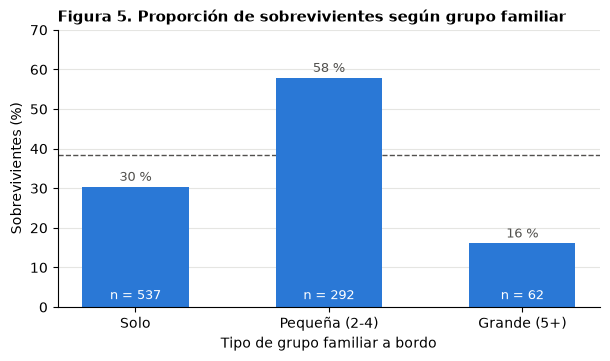

In [27]:
print(tasa(df, "tamano_familia"), "\n")
p4 = tasa(df, "tipo_familia")
print(p4)

fig, ax = plt.subplots(figsize=(7, 3.6))
barras = ax.bar(p4.index.astype(str), p4["sobrevive"], color=AZUL, width=0.55)
etiquetar(ax, barras)
for b, n in zip(barras, p4["n"]):
    ax.text(b.get_x() + b.get_width() / 2, 2, f"n = {n}", ha="center", fontsize=9, color="white")
ax.axhline(38.4, color=GRIS, linewidth=1, linestyle="--", zorder=0.5)
ax.set(xlabel="Tipo de grupo familiar a bordo", ylabel="Sobrevivientes (%)", ylim=(0, 70))
ax.set_title("Figura 5. Proporción de sobrevivientes según grupo familiar", loc="left", fontweight="bold")
plt.show()

**Interpretación.** La relación no es lineal. Quienes viajaban solos sobrevivieron menos (30,4 %) que quienes iban en familias pequeñas de 2 a 4 personas (57,9 %), pero las familias grandes (5 o más) tuvieron la menor proporción (16,1 %). Viajar solo coincide con ser hombre adulto, y las familias grandes viajaban sobre todo en 3.ª clase, por lo que este patrón podría explicarse en parte por P1; se revisará en la fase bivariada.

### 6.5 P5 · ¿Dónde se concentran los faltantes y qué pasaría si se eliminan? (Figura 6, Tabla P5)
**Pregunta:** ¿los faltantes de `age` y `deck` se concentran en alguna clase y, de ser así, eliminar esas filas distorsionaría las conclusiones sobre quién sobrevivió?

Faltantes (%) por clase:
         edad_faltante  cubierta_faltante
pclass                                  
1                13.9               19.0
2                 6.0               91.3
3                27.7               97.6 

Supervivencia (%) según si hay cubierta registrada:
                    sobrevive    n
cabina_registrada                
False                   29.9  688
True                    67.0  203


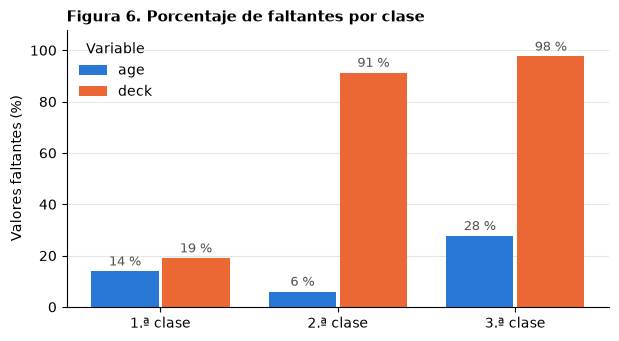

In [28]:
p5 = df.groupby("pclass").agg(
    edad_faltante=("edad_faltante", "mean"),
    cubierta_faltante=("cabina_registrada", lambda s: 1 - s.mean()),
).mul(100).round(1)
print("Faltantes (%) por clase:\n", p5, "\n")
print("Supervivencia (%) según si hay cubierta registrada:\n", tasa(df, "cabina_registrada"))

fig, ax = plt.subplots(figsize=(7, 3.6))
x, w = np.arange(3), 0.38
b1 = ax.bar(x - w / 2 - 0.01, p5["edad_faltante"], w, color=AZUL, label="age")
b2 = ax.bar(x + w / 2 + 0.01, p5["cubierta_faltante"], w, color=NARANJO, label="deck")
etiquetar(ax, b1); etiquetar(ax, b2)
ax.set(xticks=x, xticklabels=["1.ª clase", "2.ª clase", "3.ª clase"], ylabel="Valores faltantes (%)", ylim=(0, 108))
ax.legend(title="Variable", frameon=False, loc="upper left")
ax.set_title("Figura 6. Porcentaje de faltantes por clase", loc="left", fontweight="bold")
plt.show()

**Acción complementaria:** se simula qué pasaría si, en lugar de conservar los faltantes (D4 y D5), se eliminaran las filas incompletas. Se compara la proporción de sobrevivientes y la composición por clase del conjunto completo con la de cada versión recortada. La simulación no modifica `df`.

In [29]:
def resumen_escenario(d: pd.DataFrame, nombre: str) -> dict:
    comp = d["pclass"].value_counts(normalize=True).sort_index().mul(100).round(1)
    return {"escenario": nombre, "pasajeros": len(d),
            "sobrevive_%": round(d["survived"].mean() * 100, 1),
            "1.ª_%": comp.get(1, 0.0), "2.ª_%": comp.get(2, 0.0), "3.ª_%": comp.get(3, 0.0)}

escenarios = pd.DataFrame([
    resumen_escenario(df, "Conjunto completo (decisión adoptada)"),
    resumen_escenario(df.dropna(subset=["age"]), "Eliminar filas sin age"),
    resumen_escenario(df.dropna(subset=["deck"]), "Eliminar filas sin deck"),
]).set_index("escenario")
print("Tabla P5. Efecto de eliminar las filas con faltantes")
escenarios

Tabla P5. Efecto de eliminar las filas con faltantes


,pasajeros,sobrevive_%,1.ª_%,2.ª_%,3.ª_%
escenario,,,,,
Conjunto completo (decisión adoptada),891,38.4,24.2,20.7,55.1
Eliminar filas sin age,714,40.6,26.1,24.2,49.7
Eliminar filas sin deck,203,67.0,86.2,7.9,5.9


**Interpretación.** La proporción de faltantes varía según la clase. `deck` falta en el 19,0 % de la 1.ª clase y en más del 90 % de la 2.ª y 3.ª; `age` falta sobre todo en 3.ª clase (27,7 %). Por eso, **eliminar esas filas sí distorsionaría las conclusiones** (Tabla P5): sin las 177 filas sin edad, la 3.ª clase baja de 55,1 % a 49,7 % del conjunto y la supervivencia sube de 38,4 % a 40,6 %; sin las filas sin cubierta quedarían solo 203 pasajeros, el 86,2 % de 1.ª clase, y la supervivencia aparente sería de 67,0 %. En ambos casos se sobrestimaría la supervivencia porque se excluye justamente al grupo que menos sobrevivió. Esto confirma las decisiones D4 y D5 (conservar y marcar los faltantes) y obliga a elegir el método de imputación de la próxima fase según la clase.

### 6.6 Resumen: preguntas, acciones y resultados

| Pregunta | Acción (sección) | Resultado principal |
|---|---|---|
| P1 | Proporciones por sexo y clase (6.1, Figura 2) | Mujeres 74,2 % frente a hombres 18,9 %; 1.ª clase 63,0 % frente a 3.ª 24,2 % |
| P2 | Medianas de edad y proporción por grupo etario (6.2, Figura 3) | Misma mediana (28 años); los menores de 16 años sobreviven más (59,0 %) |
| P3 | Mediana de tarifa dentro de cada clase (6.3, Figura 4) | Los sobrevivientes pagaron más en 1.ª y 2.ª clase; en 3.ª las medianas fueron cercanas: 8,52 y 8,05 libras.|
| P4 | Proporción por tipo de grupo familiar (6.4, Figura 5) | Familias pequeñas 57,9 %; solos 30,4 %; familias grandes 16,1 % |
| P5 | Faltantes por clase y simulación de eliminar filas (3.4, 6.5, Figura 6, Tabla P5) | `deck` y `age` faltan sobre todo en 2.ª y 3.ª clase; eliminarlas elevaría la supervivencia de 38,4 % a 40,6 % (sin `age`) o 67,0 % (sin `deck`) |

## VII. Supuestos y limitaciones

**Supuestos considerados**
- Cada fila corresponde a un pasajero distinto, aunque haya filas idénticas (D1; respaldado por el `PassengerId` único del archivo de Kaggle).
- Los valores registrados son correctos salvo evidencia en contra; por eso las 15 tarifas en cero se conservan y solo se marcan (D7).
- La tarifa corresponde al ticket y puede cubrir a varios pasajeros; las comparaciones de tarifa son, por tanto, aproximadas (P3).
- El corte de 16 años para «niño» se toma del propio dataset (`who`), no de una fuente histórica (D8).

**Limitaciones detectadas**
- **Datos:** son los 891 pasajeros del conjunto de entrenamiento (Kaggle reserva otros 418 para prueba) y no incluyen a la tripulación; los resultados describen esta muestra y no se generalizan a todos los ocupantes del barco.
- **Faltantes:** `deck` (77,2 %) no permite analizar la ubicación del camarote, y los faltantes de `age` dependen de la clase y de la supervivencia (6.2 y 6.5).
- **Subgrupos pequeños:** Queenstown (77 pasajeros), familias de 5 o más (62) y tarifas en cero (15) entregan proporciones inestables.
- **Proceso:** todos los resultados son descriptivos (proporciones y medianas); no se calculan intervalos de confianza ni se controla por otras variables, por lo que no permiten afirmar causalidad.

**Aspectos pendientes que condicionan las fases siguientes**
- Elegir el método de imputación de `age` considerando su relación con la clase y la supervivencia (D4).
- Separar los efectos de sexo, clase y grupo familiar con análisis bivariados y tablas cruzadas (P1 y P4).
- Decidir si `deck` se descarta o se reemplaza definitivamente por `cabina_registrada` (D5).

## VIII. Cierre del avance

**Síntesis del trabajo.** Se cargó el dataset desde una copia local fija, se revisaron su estructura y calidad (sección III), se describieron sus variables (sección IV), se tomaron y documentaron ocho decisiones de limpieza y transformación con su resultado intermedio (sección V, bitácora 5.9) y se respondieron de forma preliminar las cinco preguntas exploratorias (sección VI). El resultado es un conjunto procesado de 891 × 16 guardado en `data/processed/titanic_fase1.csv`.

**Principales hallazgos de la fase**
1. El sexo y la clase son los factores más asociados a la supervivencia; su combinación separa con fuerza los grupos (mujeres de 1.ª clase: 96,8 %; hombres de 3.ª: 13,5 %).
2. La edad influye sobre todo en los menores de 16 años (59,0 %).
3. La tarifa aporta información dentro de 1.ª y 2.ª clase, y la relación con el grupo familiar no es lineal.
4. Los faltantes de `age` y `deck` dependen de la clase: no pueden tratarse como aleatorios y eliminarlos sobrestimaría la supervivencia (de 38,4 % a 40,6 % sin `age`), por lo que se conservan hasta definir la imputación.

**Proyección.** La Fase 2 partirá de `titanic_fase1.csv` para evaluar la imputación de `age`, profundizar el análisis univariado y bivariado con tablas cruzadas entre sexo, clase y familia, y construir tablas derivadas por grupo.

### Verificación final de reproducibilidad
**Acción:** se comprueba que el archivo procesado guardado coincide con el que generó este notebook y que la copia cruda sigue intacta.

In [30]:
releido = pd.read_csv(RUTA_PROC)
crudo = pd.read_csv(RUTA_RAW)
checks = {
    "Copia cruda con 891 x 15": crudo.shape == (891, 15),
    "Procesado con 891 x 16": releido.shape == (891, 16),
    "Mismos sobrevivientes en crudo y procesado": crudo["survived"].sum() == releido["survived"].sum() == 342,
    "Mismos faltantes de edad en crudo y procesado": crudo["age"].isna().sum() == releido["age"].isna().sum() == 177,
    "Bitácora con D0 (copia inicial) y las 8 decisiones D1-D8": len(bitacora_df) == 9,
}
for nombre, ok in checks.items():
    print(("OK   " if ok else "FALLA"), nombre)
assert all(checks.values())

OK    Copia cruda con 891 x 15
OK    Procesado con 891 x 16
OK    Mismos sobrevivientes en crudo y procesado
OK    Mismos faltantes de edad en crudo y procesado
OK    Bitácora con D0 (copia inicial) y las 8 decisiones D1-D8
